# Anàlisi de la Pressió Turística i Impacte en l'Habitatge (2023-2025)
Aquest notebook respon a dues grans preguntes de recerca:
1. **El "Campament Base":** Hi ha un augment de turistes que s'allotgen fora de Barcelona però visiten la ciutat de manera recurrent?
2. **Impacte en l'Habitatge:** Els barris que han patit un major increment de pernoctacions turístiques són els mateixos on més han pujat els preus del lloguer i la compravenda?

Comencem configurant l'entorn de treball i les rutes d'accés a les dades.

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuració de les rutes relatives basades en l'estructura del projecte
datasets_dir = Path("datasets")
base_dir = datasets_dir / "output_limite_legal_turismo_v2"
search_dir = base_dir / "output_limite_legal" if (base_dir / "output_limite_legal").exists() else base_dir

print(f"Ruta de treball de turisme configurada: {search_dir}")
print(f"Directori de desat configurat: {datasets_dir}")

Ruta de treball de turisme configurada: datasets/output_limite_legal_turismo_v2
Directori de desat configurat: datasets


### 1. Càlcul d'Intensitat de Visita (Preparació pel Campament Base)
Telefónica Tech ens proporciona dos conjunts de dades per als visitants de fora de la ciutat ("excursionistes"):
- **Dades diàries:** Ens diuen el total d'entrades (dies-visita acumulats).
- **Dades mensuals:** Ens diuen quantes persones úniques (dispositius) han entrat al llarg del mes.

Aquest codi creua ambdós fitxers per saber la ràtio de dies que cada persona visita la ciutat.

In [2]:
registros_intensidad = []

for folder in sorted(search_dir.iterdir()):
    if folder.is_dir() and folder.name.isdigit():
        path_diario = folder / "visitantes_unicos_municipio_date_dt.csv"
        path_mensual = folder / "visitantes_unicos_municipio_yearmon.csv"
        
        if path_diario.exists() and path_mensual.exists():
            # A. Dades diàries (sumatori de visites totals)
            df_d = pd.read_csv(path_diario, sep=None, engine='python')
            df_d.columns = [c.strip().lower() for c in df_d.columns]
            df_d_ext = df_d[
                (df_d['origen'].astype(str).str.strip().str.lower().isin(['nacional', 'internacional'])) &
                (df_d['tipo_visitante'].astype(str).str.strip().str.lower() == 'excursionista')
            ].copy()
            df_d_ext['visitantes'] = pd.to_numeric(df_d_ext['visitantes'], errors='coerce').fillna(0)
            agg_diario = df_d_ext.groupby(['mes', 'origen'], as_index=False)['visitantes'].sum().rename(
                columns={'visitantes': 'dias_visita_totales'}
            )
            
            # B. Dades mensuals (persones úniques)
            df_m = pd.read_csv(path_mensual, sep=None, engine='python')
            df_m.columns = [c.strip().lower() for c in df_m.columns]
            df_m_ext = df_m[
                (df_m['origen'].astype(str).str.strip().str.lower().isin(['nacional', 'internacional'])) &
                (df_m['tipo_visitante'].astype(str).str.strip().str.lower() == 'excursionista')
            ].copy()
            df_m_ext['visitantes'] = pd.to_numeric(df_m_ext['visitantes'], errors='coerce').fillna(0)
            agg_mensual = df_m_ext.groupby(['mes', 'origen'], as_index=False)['visitantes'].sum().rename(
                columns={'visitantes': 'personas_unicas_mes'}
            )
            
            mes_fusion = pd.merge(agg_diario, agg_mensual, on=['mes', 'origen'])
            registros_intensidad.append(mes_fusion)

df_vol = pd.concat(registros_intensidad, ignore_index=True)
df_vol['mes'] = df_vol['mes'].astype(str)
df_vol = df_vol.sort_values(['origen', 'mes'])
print("Creuament d'intensitat completat.")

Creuament d'intensitat completat.


### 2. Model Bimodal: Aïllar el veritable "Campament Base"
Dins dels "excursionistes" hi ha molt de soroll (gent que ve d'escala a l'aeroport, creuers o passa per l'AP-7 un sol dia). 
Per saber quants turistes reals s'allotgen a la perifèria (L'Hospitalet, Badalona, etc.) i entren repetidament, apliquem una equació bimodal. 
**Justificació oficial:** Fixem que el turista "Campament Base" entra a Barcelona 3,5 dies naturals, valor basat exactament en l'estada mitjana hotelera (2,5 nits) reportada per l'Observatori del Turisme a Barcelona (OTB).

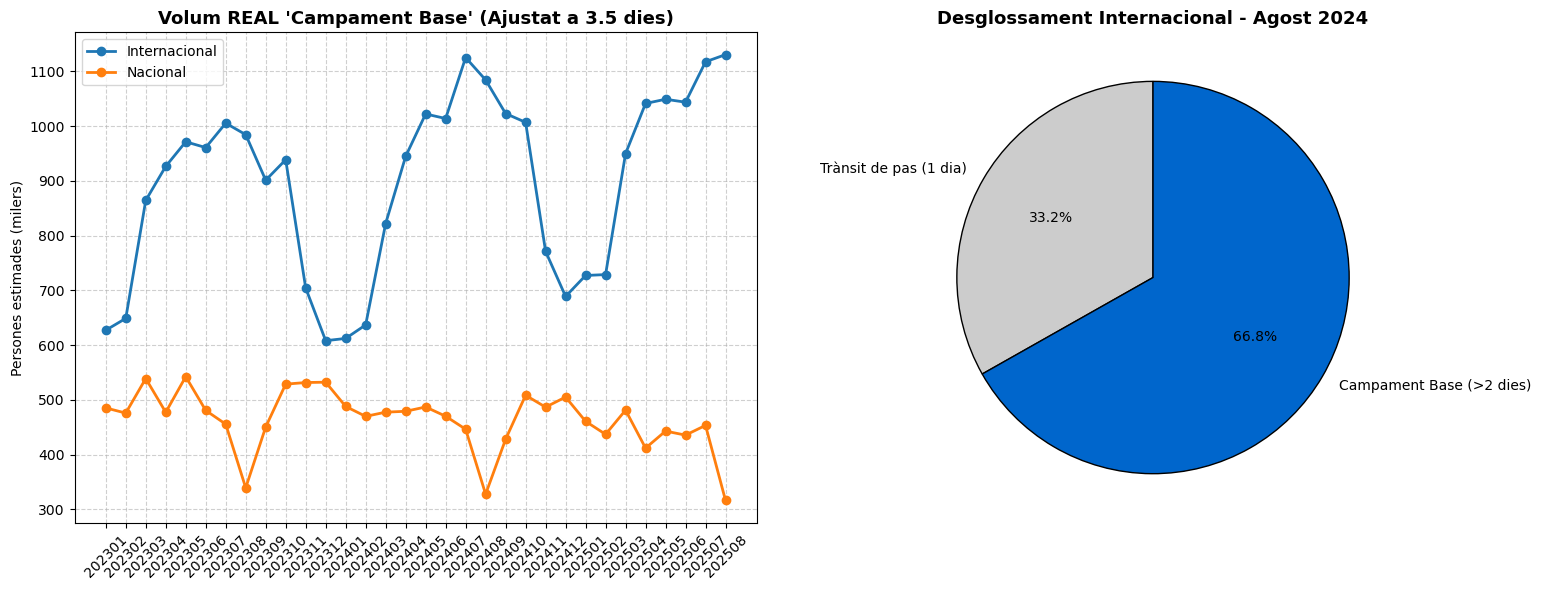

In [3]:
# Càlcul del model bimodal
media_dias_recurrente = 3.5 
df_vol['base_camp_estimados'] = (df_vol['dias_visita_totales'] - df_vol['personas_unicas_mes']) / (media_dias_recurrente - 1)
df_vol['base_camp_estimados'] = df_vol['base_camp_estimados'].clip(lower=0).round(0)
df_vol['solo_un_dia_estimados'] = df_vol['personas_unicas_mes'] - df_vol['base_camp_estimados']

# Visualització
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for origen, grp in df_vol.groupby('origen'):
    axes[0].plot(grp['mes'], grp['base_camp_estimados'] / 1000, marker='o', linewidth=2, label=f"{origen}")

axes[0].set_title("Volum REAL 'Campament Base' (Ajustat a 3.5 dies)", fontsize=13, weight='bold')
axes[0].set_ylabel("Persones estimades (milers)")
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

agosto_int = df_vol[(df_vol['mes'] == '202408') & (df_vol['origen'] == 'Internacional')].iloc[0]
axes[1].pie(
    [agosto_int['solo_un_dia_estimados'], agosto_int['base_camp_estimados']], 
    labels=['Trànsit de pas (1 dia)', 'Campament Base (>2 dies)'],
    autopct='%1.1f%%', startangle=90, colors=['#cccccc', '#0066cc'],
    wedgeprops={'edgecolor': 'black'}
)
axes[1].set_title("Desglossament Internacional - Agost 2024", fontsize=13, weight='bold')

plt.tight_layout()
plt.show()

output_estimacion = datasets_dir / "estimacion_base_camp_3_5dias.csv"
df_vol.to_csv(output_estimacion, index=False)

### 3. Consolidació de Turistes per Barri (Impacte Local)
Per respondre a la segona pregunta, necessitem extreure exclusivament la gent que **pernocta** dins de la ciutat de Barcelona (`tipo_visitante == 'turista'`), barri a barri, per poder creuar aquestes dades amb els preus de l'habitatge (lloguer i compravenda).

In [4]:
lista_df_barrio = []

for folder in sorted(search_dir.iterdir()):
    if folder.is_dir() and folder.name.isdigit():
        csv_path = folder / "visitantes_unicos_barrio_yearmon.csv"
        if csv_path.exists():
            df_mes = pd.read_csv(csv_path, sep=None, engine='python')
            df_mes.columns = [c.strip().lower() for c in df_mes.columns]
            
            # Ens quedem només amb els turistes que dormen al barri
            df_turistas = df_mes[df_mes['tipo_visitante'].str.strip().str.lower() == 'turista'].copy()
            df_turistas['visitantes'] = pd.to_numeric(df_turistas['visitantes'], errors='coerce').fillna(0)
            lista_df_barrio.append(df_turistas)

df_punto1 = pd.concat(lista_df_barrio, ignore_index=True).groupby(
    ['mes', 'cod_barrio', 'cod_municipio', 'desc_municipio'], as_index=False
)['visitantes'].sum().rename(columns={'visitantes': 'total_turistes_pernocta'})

output_barrios = datasets_dir / "turistes_barri_mes_consolidat.csv"
df_punto1.to_csv(output_barrios, index=False)
print("Dades de turisme per barri consolidades.")

Dades de turisme per barri consolidades.


### 4. Correlació: Creixement Turístic vs Creixement de Preus per barri (2023-2025)
Ara creuem les dades de turisme per barri amb els preus oficials de lloguer i compravenda. 
Calcularem l'increment percentual de cada variable entre el 2023 i el 2025 i visualitzarem els resultats per veure si existeix una correlació estadística (R de Pearson) i mostrarem el Top 10 de barris on més ha crescut el turisme.

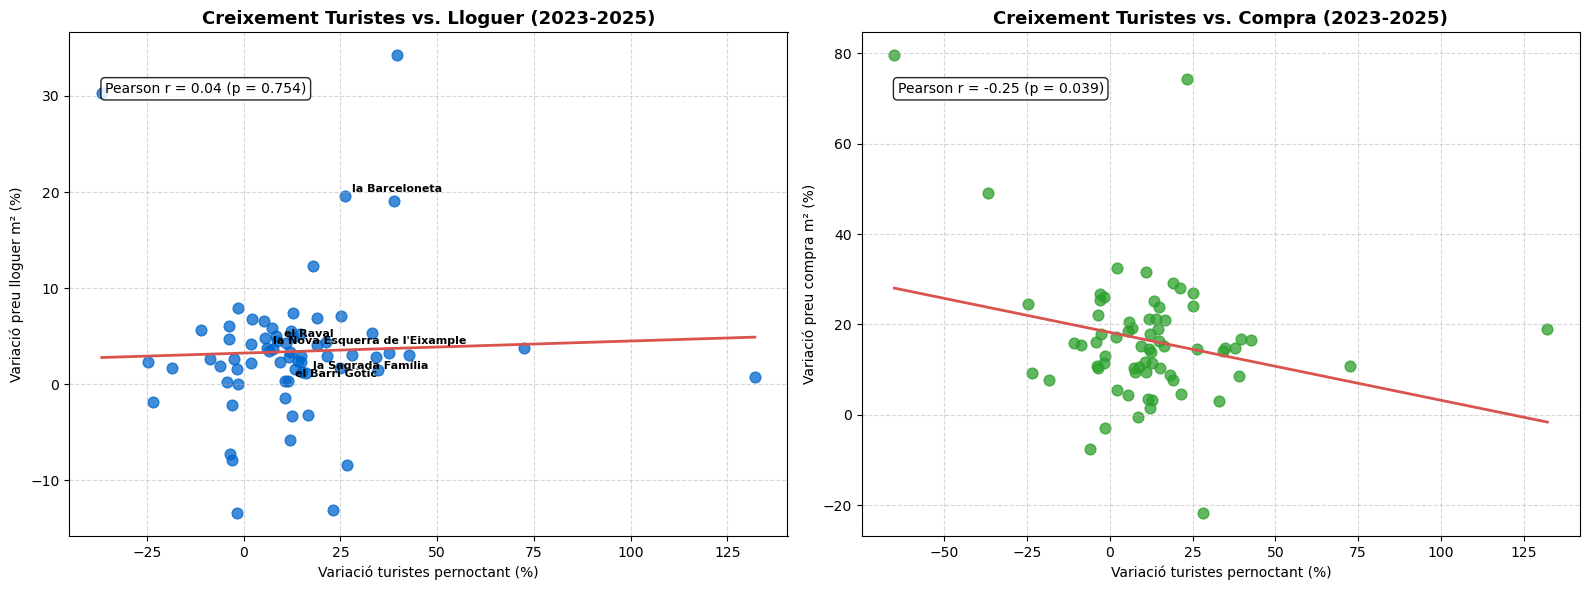


TOP 10 BARRIS AMB MAJOR CREIXEMENT TURÍSTIC (2023-2025):


,Nom,turistes_2023,turistes_2025,creixement_turistes_pct,creixement_lloguer_pct,creixement_compra_pct
11,la Font de la Guatlla,7463.58,17324.38,132.12,0.76,18.99
43,el Turó de la Peira,4814.50,8306.75,72.54,3.74,10.73
68,Provençals del Poblenou,47062.08,67178.62,42.74,3.06,16.65
51,Torre Baró,4876.17,6808.88,39.64,34.24,16.80
66,Diagonal Mar i el Front Marítim del Poblenou,73021.50,101405.75,38.87,19.03,8.64
32,el Guinardó,32955.08,45376.75,37.69,3.28,14.73
61,el Camp de l'Arpa del Clot,36316.58,48937.12,34.75,1.46,14.77
65,el Poblenou,105604.17,141768.00,34.24,2.87,14.21
67,el Besòs i el Maresme,90658.17,120619.75,33.05,5.36,3.02
54,la Trinitat Vella,11644.92,14918.88,28.11,3.03,-21.83


In [5]:
# 1. Carregar dades
df_tur = pd.read_csv(datasets_dir / "turistes_barri_mes_consolidat.csv")
df_lloguer = pd.read_csv(datasets_dir / "lloguer_2023_2025_net.csv")
df_compra = pd.read_csv(datasets_dir / "dades_preu_m2_netes.csv")

def netejar_text(s):
    return (s.astype(str).str.strip().str.lower()
            .str.replace('·', '', regex=False).str.replace("'", '', regex=False).str.replace('"', '', regex=False))

# 2. Processar evolució turisme
df_tur['any'] = df_tur['mes'].astype(str).str[:4].astype(int)
tur_2023 = df_tur[df_tur['any'] == 2023].groupby('cod_barrio')['total_turistes_pernocta'].mean().reset_index().rename(columns={'total_turistes_pernocta': 'turistes_2023'})
tur_2025 = df_tur[df_tur['any'] == 2025].groupby('cod_barrio')['total_turistes_pernocta'].mean().reset_index().rename(columns={'total_turistes_pernocta': 'turistes_2025'})
df_evol_tur = pd.merge(tur_2023, tur_2025, on='cod_barrio')
df_evol_tur['creixement_turistes_pct'] = ((df_evol_tur['turistes_2025'] - df_evol_tur['turistes_2023']) / df_evol_tur['turistes_2023']) * 100

# 3. Processar evolució lloguer
llog_barris = df_lloguer[df_lloguer['Tipus'].str.strip() == 'Barri'].copy()
llog_barris['nom_join'] = netejar_text(llog_barris['Nom'])
llog_2023 = llog_barris[llog_barris['Any'] == 2023][['nom_join', 'Nom', 'Preu_Lloguer_m2']].rename(columns={'Preu_Lloguer_m2': 'lloguer_2023'})
llog_2025 = llog_barris[llog_barris['Any'] == 2025][['nom_join', 'Preu_Lloguer_m2']].rename(columns={'Preu_Lloguer_m2': 'lloguer_2025'})
df_evol_llog = pd.merge(llog_2023, llog_2025, on='nom_join')
df_evol_llog['creixement_lloguer_pct'] = ((df_evol_llog['lloguer_2025'] - df_evol_llog['lloguer_2023']) / df_evol_llog['lloguer_2023']) * 100

# 4. Processar evolució compra
comp_barris = df_compra[df_compra['Tipus'].str.strip() == 'Barri'].copy()
comp_barris['nom_join'] = netejar_text(comp_barris['Nom'])
comp_barris['Codi'] = comp_barris['Codi'].astype(int)
comp_2023 = comp_barris[comp_barris['Any'] == 2023][['nom_join', 'Codi', 'Preu_m2_Total']].rename(columns={'Preu_m2_Total': 'compra_2023'})
comp_2025 = comp_barris[comp_barris['Any'] == 2025][['nom_join', 'Preu_m2_Total']].rename(columns={'Preu_m2_Total': 'compra_2025'})
df_evol_comp = pd.merge(comp_2023, comp_2025, on='nom_join')
df_evol_comp['creixement_compra_pct'] = ((df_evol_comp['compra_2025'] - df_evol_comp['compra_2023']) / df_evol_comp['compra_2023']) * 100

# 5. Unir dades
df_hab = pd.merge(df_evol_llog, df_evol_comp[['nom_join', 'Codi', 'compra_2023', 'compra_2025', 'creixement_compra_pct']], on='nom_join')
mapa_codi_real = {b: i + 1 for i, b in enumerate(sorted(df_evol_tur['cod_barrio'].unique()))}
df_evol_tur['Codi_real'] = df_evol_tur['cod_barrio'].map(mapa_codi_real)
df_final = pd.merge(df_evol_tur, df_hab, left_on='Codi_real', right_on='Codi', how='inner').drop_duplicates(subset=['Nom'])

# 6. Correlacions
df_net_llog = df_final.replace([np.inf, -np.inf], np.nan).dropna(subset=['creixement_turistes_pct', 'creixement_lloguer_pct'])
r_llog, p_llog = stats.pearsonr(df_net_llog['creixement_turistes_pct'], df_net_llog['creixement_lloguer_pct'])

df_net_comp = df_final.replace([np.inf, -np.inf], np.nan).dropna(subset=['creixement_turistes_pct', 'creixement_compra_pct'])
r_comp, p_comp = stats.pearsonr(df_net_comp['creixement_turistes_pct'], df_net_comp['creixement_compra_pct'])

# 7. Visualització
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.regplot(data=df_net_llog, x='creixement_turistes_pct', y='creixement_lloguer_pct', ax=axes[0], ci=None, color='#0066cc', scatter_kws={'s': 60, 'alpha': 0.75}, line_kws={'color': '#d9534f', 'linewidth': 2})
axes[0].set_title("Creixement Turistes vs. Lloguer (2023-2025)", fontsize=13, weight='bold')
axes[0].set_xlabel("Variació turistes pernoctant (%)")
axes[0].set_ylabel("Variació preu lloguer m² (%)")
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].text(0.05, 0.88, f"Pearson r = {r_llog:.2f} (p = {p_llog:.3f})", transform=axes[0].transAxes, bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

sns.regplot(data=df_net_comp, x='creixement_turistes_pct', y='creixement_compra_pct', ax=axes[1], ci=None, color='#2ca02c', scatter_kws={'s': 60, 'alpha': 0.75}, line_kws={'color': '#d9534f', 'linewidth': 2})
axes[1].set_title("Creixement Turistes vs. Compra (2023-2025)", fontsize=13, weight='bold')
axes[1].set_xlabel("Variació turistes pernoctant (%)")
axes[1].set_ylabel("Variació preu compra m² (%)")
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].text(0.05, 0.88, f"Pearson r = {r_comp:.2f} (p = {p_comp:.3f})", transform=axes[1].transAxes, bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

barris_clau = ['el Raval', 'el Barri Gòtic', 'la Barceloneta', 'la Sagrada Família', 'la Nova Esquerra de l\'Eixample']
for _, row in df_net_llog.iterrows():
    if row['Nom'] in barris_clau:
        axes[0].annotate(row['Nom'], (row['creixement_turistes_pct'], row['creixement_lloguer_pct']), xytext=(5, 3), textcoords='offset points', fontsize=8, weight='semibold')

plt.tight_layout()
plt.show()

# 8. Mostrar el Top 10 de barris on més ha crescut el turisme
cols_veure = ['Nom', 'turistes_2023', 'turistes_2025', 'creixement_turistes_pct', 'creixement_lloguer_pct', 'creixement_compra_pct']
df_top10 = df_final[cols_veure].sort_values(by='creixement_turistes_pct', ascending=False).head(10).round(2)
print("\nTOP 10 BARRIS AMB MAJOR CREIXEMENT TURÍSTIC (2023-2025):")
display(df_top10)

### 5. Correlació: Creixement Turístic vs Creixement de Preus a tota la ciutat (2023-2025)


DADES DE BARCELONA:


,Any,Turistes,Lloguer,Compra
0,2023,7.635957e+06,16.10,4370.96
1,2024,8.203683e+06,16.13,4481.77
2,2025,8.541312e+06,16.67,4797.02


Turisme vs Lloguer: r = 0.812, p = 0.396
Turisme vs Compra: r = 0.915, p = 0.265


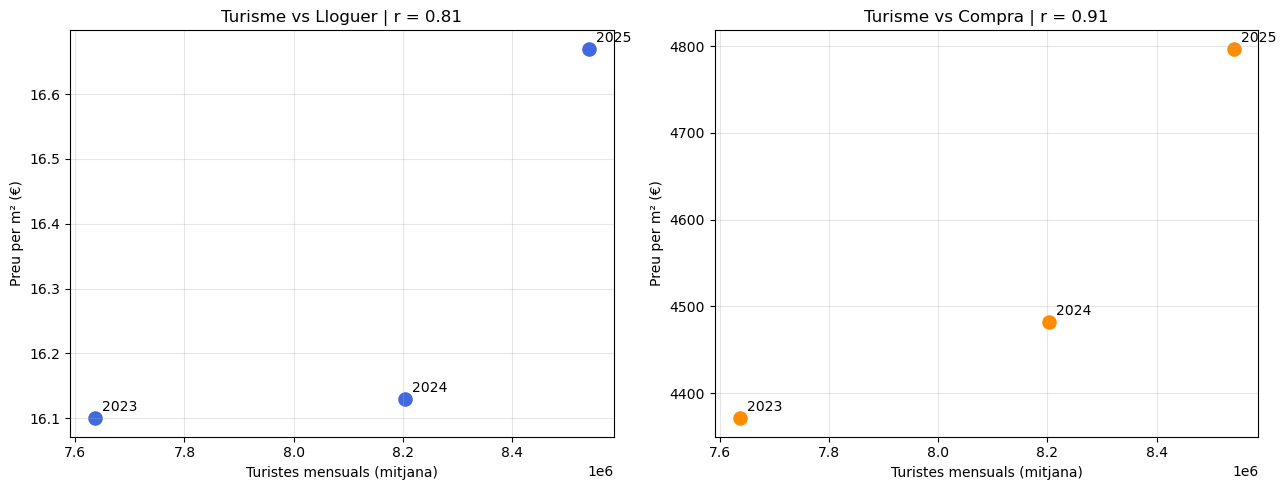

In [8]:

# CORRELACIÓ TURISME I HABITATGE - BARCELONA (2023-2025)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 1. Carregar els fitxers del notebook
tur = pd.read_csv(datasets_dir / "turistes_barri_mes_consolidat.csv")
llog = pd.read_csv(datasets_dir / "lloguer_2023_2025_net.csv")
comp = pd.read_csv(datasets_dir / "dades_preu_m2_netes.csv")

# 2. Turistes mensuals a tota Barcelona
# Sumem tots els barris, sense sumar els mesos entre si
tur["Any"] = tur["mes"].astype(str).str[:4].astype(int)

tur_mes = (
    tur.groupby(["mes", "Any"], as_index=False)
    ["total_turistes_pernocta"].sum()
)

# Mitjana mensual de cada any
tur_any = (
    tur_mes.groupby("Any", as_index=False)
    ["total_turistes_pernocta"].mean()
    .rename(columns={
        "total_turistes_pernocta": "Turistes"
    })
)

# 3. Preus de lloguer i compra de Barcelona ciutat
def filtrar_barcelona(df):
    return df[
        df["Nom"].astype(str).str.strip().str.lower().eq("barcelona")
        & df["Tipus"].astype(str).str.strip().str.lower()
            .isin(["municipi", "municipio", "ciutat"])
    ].copy()

llog_bcn = filtrar_barcelona(llog)[
    ["Any", "Preu_Lloguer_m2"]
].rename(columns={"Preu_Lloguer_m2": "Lloguer"})

comp_bcn = filtrar_barcelona(comp)[
    ["Any", "Preu_m2_Total"]
].rename(columns={"Preu_m2_Total": "Compra"})

# 4. Unir les tres variables per any
df = tur_any.merge(llog_bcn, on="Any")
df = df.merge(comp_bcn, on="Any")
df = df[df["Any"].between(2023, 2025)].sort_values("Any")

for col in ["Turistes", "Lloguer", "Compra"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("DADES DE BARCELONA:")
display(df)

# 5. Correlacions de Pearson
def correlacio(x, y):
    dades = df[[x, y]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(dades) < 3:
        print(f"No hi ha prou dades per a {y}")
        return np.nan

    if dades[x].nunique() < 2 or dades[y].nunique() < 2:
        print(f"No hi ha variació suficient per a {y}")
        return np.nan

    r, p = pearsonr(dades[x], dades[y])
    print(f"Turisme vs {y}: r = {r:.3f}, p = {p:.3f}")
    return r

r_llog = correlacio("Turistes", "Lloguer")
r_comp = correlacio("Turistes", "Compra")

# 6. Gràfics de dispersió
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, variable, r, color in [
    (axes[0], "Lloguer", r_llog, "royalblue"),
    (axes[1], "Compra", r_comp, "darkorange")
]:
    ax.scatter(df["Turistes"], df[variable],
               color=color, s=90)

    for _, fila in df.iterrows():
        ax.annotate(
            str(int(fila["Any"])),
            (fila["Turistes"], fila[variable]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    ax.set_xlabel("Turistes mensuals (mitjana)")
    ax.set_ylabel("Preu per m² (€)")
    ax.set_title(f"Turisme vs {variable} | r = {r:.2f}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Conclusions Finals del Projecte

Després d'analitzar empíricament els conjunts de dades de mobilitat i habitatge, podem donar resposta a les dues grans qüestions:

**1. Està augmentant l'allotjament turístic a la perfieria de Barcelona amb visites recurrents a la ciutat?**
Els resultats del model apunten a un augment dels visitants internacionals que entren de manera recurrent a Barcelona, tot i allotjar-se fora de la ciutat. En canvi, els visitants nacionals amb aquest patró de mobilitat presenten una evolució decreixent durant el període analitzat (Secció 2 del codi). Això suggereix que la descentralització turística de la ciutat podria estar guanyant importància, principalment per atendre la nova demanda estrangera, no per un desplaçament del turisme estatal. Tanmateix, cal tenir en compte que es tracta d'una estimació basada en la freqüència de les visites i no d'una identificació directa del lloc on s'allotgen els visitants. Per tant, els resultats permeten identificar un possible patró de mobilitat turística metropolitana, però no confirmar directament que aquests visitants s'allotgin en municipis de la perifèria.

**2. Quina és la relació barri a barri entre l'increment turístic i el preu de l'habitatge?**
La hipòtesi que l'augment del preu de l'habitatge es concentra principalment en els barris on més creix el turisme **queda descartada**:
- **Absència de correlació en lloguer ($r = 0.04$):** Com es pot veure a la taula del Top 10, barris molt tensionats turísticament com el **Barri Gòtic** (+11.44% en turistes) o la **Sagrada Família** (+16.23% en turistes) han tingut creixements del lloguer pràcticament plans (+0.30% i +1.14% respectivament). 
Una possible explicació és que aquests barris ja partien de nivells de preus elevats a causa de la pressió turística i immobiliària acumulada durant els anys anteriors. Per tant, l'augment actual dels preus podria estar reflectint una tendència general d'encariment de l'habitatge a Barcelona, que també afecta barris amb una presència turística menys elevada. Aquesta hipòtesi, però, no es pot confirmar únicament amb les dades analitzades, ja que no disposem d'una comparació de l'evolució dels preus durant un període més llarg.

- **Efecte Expulsió (Spillover) en compravenda ($r = -0.25$):** Existeix una relació lineal *negativa*. Els barris on més està pujant el preu del metre quadrat (com Sant Antoni amb un +21.27% o la Nova Esquerra de l'Eixample amb un +20.47%) són zones residencials on l'increment de pernoctacions turístiques és més moderat. Aquest comportament podria estar relacionat amb una possible redistribució de la demanda residencial cap a altres zones de la ciutat, com a conseqüència de l'elevada pressió immobiliària dels barris més turístics. Tanmateix, la correlació negativa observada no permet demostrar directament l'existència d'aquest efecte d'expulsió (spillover), ja que també hi poden intervenir altres factors econòmics i immobiliaris.

**3. Encara que no hi hagi correlació entre el turisme i els preus barri per barri, pot existir una relació entre el creixement del turisme a Barcelona en conjunt i l'encariment general de l'habitatge a tota la ciutat?**
L'anàlisi de Barcelona en conjunt mostra una correlació positiva elevada entre el creixement del turisme i l'augment dels preus de l'habitatge, tant en el lloguer (r = 0,81) com en la compravenda (r = 0,91), a diferència dels resultats obtinguts barri per barri. Tot i que aquestes correlacions no són estadísticament significatives, ja que només disposem de dades de tres anys, considerem interessant estudiar aquesta relació amb les dades disponibles per donar suport a la hipòtesi que l'encariment de l'habitatge és un fenomen generalitzat a Barcelona, i no exclusiu dels barris amb més creixement turístic. Tanmateix, no podem afirmar que el turisme sigui la causa directa d'aquest encariment.


En conjunt, els resultats suggereixen que l'augment dels preus de l'habitatge a Barcelona no es pot explicar únicament pel creixement de l'activitat turística de cada barri. L'encariment de l'habitatge sembla respondre a una dinàmica més àmplia que afecta el conjunt de la ciutat, tot i que la pressió turística acumulada podria continuar tenint un paper en l'evolució dels preus.